# Results overview

Tables and charts for every experiment recorded in `results/`. Reads only the committed aggregate files (summaries, analyses, scored requests, reports), so it runs on a fresh clone without the withheld row-level logs, the datasets, or an API key. It makes no model calls.

| Round | Folder | What it tested |
|---|---|---|
| 1. Counting pilot | `luna_pilot_20261014T031651Z/` | Count rows and survivors in Titanic tables (CSV vs JSON) |
| 2. Lookup study | `week4_lookup/` | Copy three cells by record ID; 4 formats × named/neutral × original/altered |
| 3. Knowledge follow-up | `week4_followup/` (counts in `week4_overview/`) | Recall values with no table; look up three famous Titanic rows |
| 4. Selection and joins | `week4_selection/` | Find rows by 2–3 attributes, or through two linked tables |
| Round 2 on new datasets | `round2_newdata/` | Round 2's design on IBM HR, avocado, and credit card data |

See `methodology/` for the design and limitations of each round.

In [1]:
import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Resolve paths from the repository root, wherever the notebook is opened from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
RESULTS = ROOT / "results"
PILOT_DIR = RESULTS / "luna_pilot_20261014T031651Z"


def load(path):
    return json.loads((RESULTS / path).read_text(encoding="utf-8"))


pilot = load("luna_pilot_20261014T031651Z/summary.json")
lookup = load("week4_lookup/analysis.json")        # Round 2
week4 = load("week4_overview/summary.json")        # Rounds 2 and 3 combined, incl. counting and knowledge probes
selection = load("week4_selection/summary.json")   # Round 4
newdata = load("round2_newdata/analysis.json")     # Round 2 design on new datasets

FORMATS = ["csv", "json", "xml", "txt"]
STUDIES = {  # label: lookup-style analysis.json with paired contrasts
    "Round 2": lookup,
    "Round 2, new datasets": newdata,
}

SURFACE, INK, MUTED, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#c3c2b7"
# One fixed color per format everywhere in this notebook (categorical slots 1-4, in order)
FORMAT_COLORS = {"csv": "#2a78d6", "json": "#eb6834", "xml": "#1baf7a", "txt": "#eda100"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 10, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})


def fraction(correct, n):
    return f"{correct}/{n} ({100 * correct / n:.1f}%)" if n else "–"

## 1. Every round at a glance

*Fully correct* means every requested value in the reply matched. For no-table probes that means the model recalled the original values. Costs are the scripts' own estimates from token usage.

In [2]:
r3_stages = ["canonical_lookup", "canonical_prior", "prior_repaired"]
r2_stages = {k: v for k, v in lookup["stages"].items()}
batches = selection["batches"]

overview = pd.DataFrame([
    dict(round="1. Counting pilot", date="2026-10-13", model="gpt-6-luna", requests=pilot["trials"],
         completed=pilot["trials"], fully_correct=f'{pilot["table_all_correct"]} of {pilot["table_trials"]} table requests',
         est_cost_usd=pilot["estimated_cost_usd"]),
    dict(round="2. Lookup study", date="2026-10-21", model="gpt-5.6-luna", requests=lookup["requests"],
         completed=lookup["status"].get("completed", 0),
         fully_correct=f'{sum(s["all_correct"] for s in r2_stages.values())} of {lookup["requests"]}',
         est_cost_usd=lookup["estimated_usd"]),
    dict(round="3. Knowledge follow-up", date="2026-10-21", model="gpt-5.6-luna",
         requests=sum(week4["stages"][s]["requests"] for s in r3_stages),
         completed=sum(week4["stages"][s]["completed"] for s in r3_stages),
         fully_correct=f'{sum(week4["stages"][s]["whole_answer_correct"] for s in r3_stages)} of '
                       f'{sum(week4["stages"][s]["requests"] for s in r3_stages)}',
         est_cost_usd=week4["observed_estimated_usd"] - lookup["estimated_usd"]),
    dict(round="4. Selection and joins", date="2026-10-21", model=selection["model"],
         requests=sum(b["recorded"] for b in batches.values()),
         completed=sum(b["status"].get("completed", 0) for b in batches.values()),
         fully_correct=f'{sum(b["strict_correct"] for b in batches.values())} of {sum(b["recorded"] for b in batches.values())}',
         est_cost_usd=sum(b["estimated_usd"] for b in batches.values())),
    dict(round="Round 2 design, new datasets", date="2026-10-25", model="gpt-5.6-luna", requests=newdata["requests"],
         completed=newdata["status"].get("completed", 0),
         fully_correct=f'{sum(s["all_correct"] for s in newdata["stages"].values())} of {newdata["requests"]}',
         est_cost_usd=newdata["estimated_usd"]),
]).set_index("round")
overview.round({"est_cost_usd": 3})

,date,model,requests,completed,fully_correct,est_cost_usd
round,,,,,,
1. Counting pilot,2026-10-13,gpt-6-luna,20,20,9 of 16 table requests,0.011
2. Lookup study,2026-10-21,gpt-5.6-luna,358,352,349 of 358,0.396
3. Knowledge follow-up,2026-10-21,gpt-5.6-luna,24,24,19 of 24,0.022
4. Selection and joins,2026-10-21,gpt-5.6-luna,552,552,540 of 552,1.294
"Round 2 design, new datasets",2026-10-25,gpt-5.6-luna,340,340,340 of 340,0.416


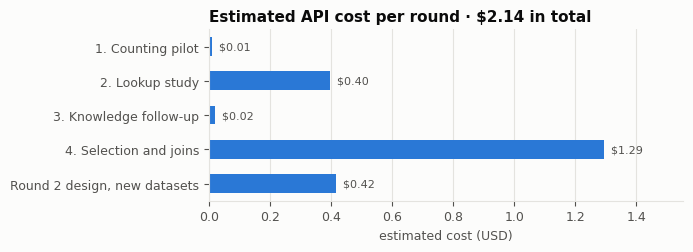

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.6))
costs = overview["est_cost_usd"][::-1]
ax.barh(costs.index, costs, color=FORMAT_COLORS["csv"], height=0.55)
for y, value in enumerate(costs):
    ax.text(value, y, f"  ${value:.2f}", va="center", color=MUTED, fontsize=8)
ax.set_xlabel("estimated cost (USD)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, costs.max() * 1.2)
ax.set_title(f"Estimated API cost per round · ${costs.sum():.2f} in total", loc="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

## 2. Counting: where the model failed

Rounds 1 and 2 asked for the number of rows and of survivors (`survived = 1`). Each dot is one reply: how far its survivor count was from the true count in the supplied table. Rings mark replies that returned the full Titanic training set's **891 rows / 342 survivors**, the familiar answer, instead of the supplied table's numbers. Round 1 used `gpt-6-luna`, Round 2 `gpt-5.6-luna`, with different prompts.

In [4]:
# Round 1's per-table answers are only published as the Results table in its REPORT.md (the trial log is withheld)
report = (PILOT_DIR / "REPORT.md").read_text(encoding="utf-8")
section = report.split("## Results", 1)[1].split("\n## ", 1)[0]
counting = []
for line in section.splitlines():
    cells = [c.strip() for c in line.strip().strip("|").split("|")]
    if len(cells) != 4 or not re.search(r"\d", cells[1]):
        continue  # header and separator rows
    true_rows, true_pos = map(int, re.findall(r"\d+", cells[1]))
    for fmt, cell in zip(["csv", "json"], cells[2:]):
        for rows, pos in re.findall(r"(\d+)\s*/\s*(\d+)", cell):
            counting.append(dict(round="Round 1", table=cells[0], format=fmt, true_rows=true_rows, true_pos=true_pos,
                                 returned_rows=int(rows), returned_pos=int(pos)))

for a in week4["arithmetic"]:
    _, dataset, n, fmt = a["id"].split("_")
    counting.append(dict(round="Round 2", table=f"{dataset.capitalize()}, {n} rows", format=fmt,
                         true_rows=a["expected"]["n_rows"], true_pos=a["expected"]["n_positive"],
                         returned_rows=a["actual"]["n_rows"], returned_pos=a["actual"]["n_positive"]))

counting = pd.DataFrame(counting)
counting["correct"] = (counting["returned_rows"] == counting["true_rows"]) & (counting["returned_pos"] == counting["true_pos"])
counting["familiar_answer"] = ((counting["returned_rows"] == 891) & (counting["returned_pos"] == 342)
                               & ~((counting["true_rows"] == 891) & (counting["true_pos"] == 342)))
counting

,round,table,format,true_rows,true_pos,returned_rows,returned_pos,correct,familiar_answer
0,Round 1,"Synthetic, 20 rows",csv,20,7,20,7,True,False
1,Round 1,"Synthetic, 20 rows",json,20,7,20,7,True,False
2,Round 1,"Synthetic, 100 rows",csv,100,34,100,34,True,False
3,Round 1,"Synthetic, 100 rows",json,100,34,100,34,True,False
4,Round 1,"Titanic sample, original; two runs per format",csv,100,38,100,38,True,False
5,Round 1,"Titanic sample, original; two runs per format",csv,100,38,100,38,True,False
6,Round 1,"Titanic sample, original; two runs per format",json,100,38,100,37,False,False
7,Round 1,"Titanic sample, original; two runs per format",json,100,38,100,38,True,False
8,Round 1,"Titanic sample, modified; two runs per format",csv,100,58,100,58,True,False
9,Round 1,"Titanic sample, modified; two runs per format",csv,100,58,100,58,True,False


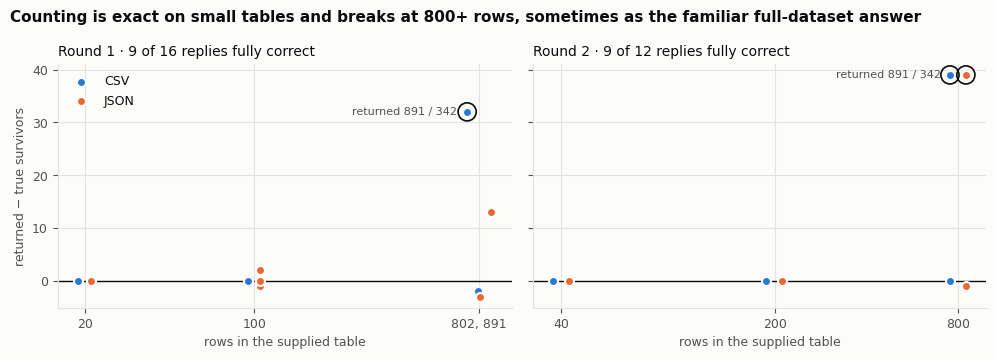

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, g) in zip(axes, counting.groupby("round")):
    ax.axhline(0, color=INK, linewidth=1, zorder=1)
    for fmt, shift in [("csv", 0.94), ("json", 1.06)]:
        d = g[g["format"] == fmt]
        ax.scatter(d["true_rows"] * shift, d["returned_pos"] - d["true_pos"], s=42, color=FORMAT_COLORS[fmt],
                   edgecolor=SURFACE, linewidth=1.5, zorder=3, label=fmt.upper())
        fam = d[d["familiar_answer"]]
        ax.scatter(fam["true_rows"] * shift, fam["returned_pos"] - fam["true_pos"], s=170, facecolor="none",
                   edgecolor=INK, linewidth=1.2, zorder=4)
    for _, row in g[g["familiar_answer"]].drop_duplicates("true_rows").iterrows():
        ax.annotate("returned 891 / 342", xy=(row["true_rows"], row["returned_pos"] - row["true_pos"]),
                    xytext=(-12, 0), textcoords="offset points", ha="right", va="center", color=MUTED, fontsize=8)
    ticks = []  # one label for sizes too close to label separately, e.g. 802 and 891
    for size in sorted(set(g["true_rows"])):
        if ticks and size / ticks[-1][-1] < 1.2:
            ticks[-1].append(size)
        else:
            ticks.append([size])
    ax.set_xscale("log")
    ax.set_xticks([math.prod(t) ** (1 / len(t)) for t in ticks], [", ".join(map(str, t)) for t in ticks])
    ax.minorticks_off()
    ax.set_xlabel("rows in the supplied table")
    ax.set_title(f"{name} · {g['correct'].sum()} of {len(g)} replies fully correct", loc="left")
axes[0].set_ylabel("returned − true survivors")
axes[0].legend(loc="upper left")
fig.suptitle("Counting is exact on small tables and breaks at 800+ rows, sometimes as the familiar full-dataset answer",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

## 3. Lookup: accuracy by format

Present-cell accuracy in the primary comparison of each lookup study: the share of requested values copied correctly. Rounds 2 and the new-dataset run look up by record ID; Round 4 selects rows by attributes (*attribute*) or through a second linked table (*join*). *Reversions* are altered cells answered with the replaced original value.

In [6]:
lookup_rows = []
for study, analysis in STUDIES.items():
    for fmt in FORMATS:
        g = analysis["primary_by_format"][fmt]
        lookup_rows.append(dict(study=study, format=fmt, present=g["correct"], present_n=g["n"],
                                altered=g["altered_correct"], altered_n=g["altered_n"], reversions=g["reversions"]))
for task, by_format in selection["primary"].items():
    for fmt in FORMATS:
        g = by_format[fmt]
        lookup_rows.append(dict(study=f"Round 4, {task}", format=fmt, present=g["present_correct"], present_n=g["present_n"],
                                altered=g["altered_correct"], altered_n=g["altered_n"], reversions=g["reversions"],
                                absent=g["absent_correct"], absent_n=g["absent_n"]))
lookup_by_format = pd.DataFrame(lookup_rows)
lookup_by_format["accuracy_pct"] = 100 * lookup_by_format["present"] / lookup_by_format["present_n"]

(lookup_by_format.assign(cells=[fraction(c, n) for c, n in zip(lookup_by_format["present"], lookup_by_format["present_n"])])
 .pivot(index="study", columns="format", values="cells")[FORMATS])

format,csv,json,xml,txt
study,,,,
Round 2,216/216 (100.0%),216/216 (100.0%),216/216 (100.0%),216/216 (100.0%)
"Round 2, new datasets",216/216 (100.0%),216/216 (100.0%),216/216 (100.0%),216/216 (100.0%)
"Round 4, attribute",144/144 (100.0%),143/144 (99.3%),143/144 (99.3%),144/144 (100.0%)
"Round 4, join",144/144 (100.0%),144/144 (100.0%),144/144 (100.0%),144/144 (100.0%)


In [7]:
# Altered cells and reversions to the original value, same studies
(lookup_by_format.assign(altered_cells=[fraction(c, n) for c, n in zip(lookup_by_format["altered"], lookup_by_format["altered_n"])])
 .pivot(index="study", columns="format", values="altered_cells")[FORMATS]
 .assign(reversions=lookup_by_format.groupby("study", sort=False)["reversions"].sum()))

format,csv,json,xml,txt,reversions
study,,,,,
Round 2,108/108 (100.0%),108/108 (100.0%),108/108 (100.0%),108/108 (100.0%),0
"Round 2, new datasets",108/108 (100.0%),108/108 (100.0%),108/108 (100.0%),108/108 (100.0%),0
"Round 4, attribute",72/72 (100.0%),72/72 (100.0%),71/72 (98.6%),72/72 (100.0%),0
"Round 4, join",72/72 (100.0%),72/72 (100.0%),72/72 (100.0%),72/72 (100.0%),0


### Paired contrasts

Each study's analysis compares conditions within the same sampled tables, then summarizes uncertainty with a block bootstrap. Dots are the mean difference in present-cell accuracy, lines the descriptive 95% interval. Every interval sits on or next to zero: at ceiling accuracy these designs cannot separate the formats, and a zero-width interval does not show the formats are equivalent.

In [8]:
CONTRASTS = ["json_minus_csv", "xml_minus_csv", "txt_minus_csv", "named_minus_neutral", "altered_minus_original",
             "join_minus_attribute"]
contrast_rows = []
for study, analysis in STUDIES.items():
    for name, c in analysis["paired_contrasts"].items():
        contrast_rows.append(dict(study=study, contrast=name, difference_pp=c["difference_pp"],
                                  low=c["descriptive_bootstrap_95_percentile_pp"][0],
                                  high=c["descriptive_bootstrap_95_percentile_pp"][1], blocks=c["blocks"]))
for name, c in selection["contrasts"].items():
    contrast_rows.append(dict(study="Round 4", contrast=name, difference_pp=c["difference_pp"],
                              low=c["descriptive_95_percentile_pp"][0], high=c["descriptive_95_percentile_pp"][1],
                              blocks=c["blocks"]))
contrasts = pd.DataFrame(contrast_rows)
contrasts.round(2)

,study,contrast,difference_pp,low,high,blocks
0,Round 2,json_minus_csv,0.00,0.00,0.00,18
1,Round 2,xml_minus_csv,0.00,0.00,0.00,18
2,Round 2,txt_minus_csv,0.00,0.00,0.00,18
3,Round 2,named_minus_neutral,0.00,0.00,0.00,18
4,Round 2,altered_minus_original,0.00,0.00,0.00,18
5,"Round 2, new datasets",json_minus_csv,0.00,0.00,0.00,18
6,"Round 2, new datasets",xml_minus_csv,0.00,0.00,0.00,18
7,"Round 2, new datasets",txt_minus_csv,0.00,0.00,0.00,18
8,"Round 2, new datasets",named_minus_neutral,0.00,0.00,0.00,18
9,"Round 2, new datasets",altered_minus_original,0.00,0.00,0.00,18


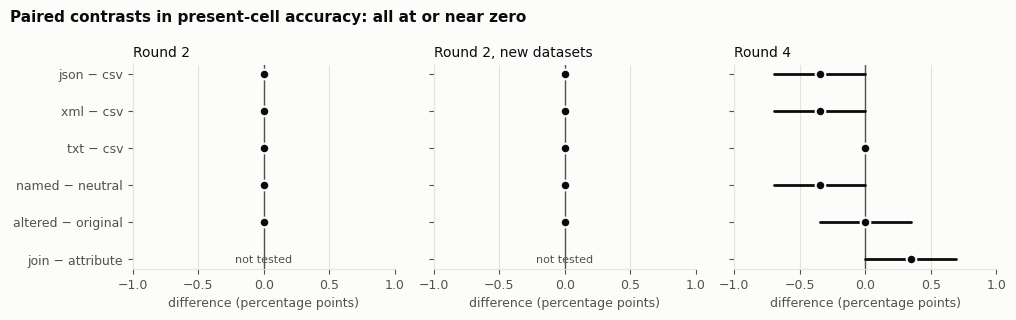

In [9]:
studies = list(dict.fromkeys(contrasts["study"]))
limit = max(1.0, contrasts[["low", "high"]].abs().max().max() * 1.3)
labels = [c.replace("_minus_", " − ").replace("_", " ") for c in CONTRASTS]

fig, axes = plt.subplots(1, len(studies), figsize=(3.4 * len(studies), 3.2), sharey=True, sharex=True)
for ax, study in zip(axes, studies):
    d = contrasts[contrasts["study"] == study].set_index("contrast")
    ax.axvline(0, color=MUTED, linewidth=1, zorder=1)
    for y, name in enumerate(CONTRASTS):
        if name not in d.index:
            ax.text(0, y, "not tested", ha="center", va="center", color=MUTED, fontsize=8)
            continue
        c = d.loc[name]
        ax.plot([c["low"], c["high"]], [y, y], color=INK, linewidth=2, solid_capstyle="round", zorder=2)
        ax.scatter(c["difference_pp"], y, s=48, color=INK, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.set_title(study, loc="left")
    ax.set_xlim(-limit, limit)
    ax.set_xlabel("difference (percentage points)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(CONTRASTS)), labels)
axes[0].invert_yaxis()
fig.suptitle("Paired contrasts in present-cell accuracy: all at or near zero", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

## 4. Prompt length by format

The same table costs very different numbers of input tokens in each format, so a format comparison is also a prompt-length comparison. Means over the primary lookup requests, from `scored_requests.csv`.

In [10]:
token_rows = []
for study, folder in [("Round 2", "week4_lookup"), ("Round 2, new datasets", "round2_newdata")]:
    scored = pd.read_csv(RESULTS / folder / "scored_requests.csv")
    main = scored[scored["stage"] == "main"]
    for fmt, g in main.groupby("format"):
        token_rows.append(dict(study=study, format=fmt, mean_input_tokens=g["input_tokens"].mean(), requests=len(g)))
tokens = pd.DataFrame(token_rows)
tokens.pivot(index="study", columns="format", values="mean_input_tokens")[FORMATS].round(0)

format,csv,json,xml,txt
study,,,,
Round 2,2249.0,4090.0,6362.0,4466.0
"Round 2, new datasets",2833.0,4587.0,6796.0,4972.0


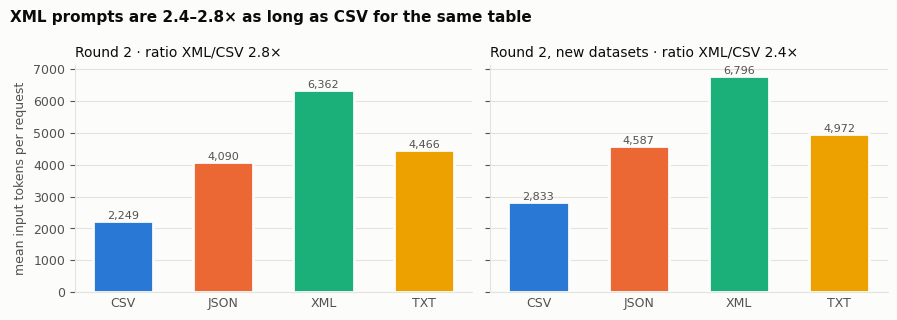

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (study, g) in zip(axes, tokens.groupby("study", sort=False)):
    g = g.set_index("format").loc[FORMATS]
    bars = ax.bar(FORMATS, g["mean_input_tokens"], color=[FORMAT_COLORS[f] for f in FORMATS], width=0.6,
                  edgecolor=SURFACE, linewidth=2)
    for bar, value in zip(bars, g["mean_input_tokens"]):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,.0f}", ha="center", va="bottom", color=MUTED, fontsize=8)
    ax.set_xticks(range(len(FORMATS)), [f.upper() for f in FORMATS])
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{study} · ratio XML/CSV {g.loc['xml', 'mean_input_tokens'] / g.loc['csv', 'mean_input_tokens']:.1f}×",
                 loc="left")
axes[0].set_ylabel("mean input tokens per request")
ratios = tokens.pivot(index="study", columns="format", values="mean_input_tokens").eval("xml / csv")
fig.suptitle(f"XML prompts are {ratios.min():.1f}–{ratios.max():.1f}× as long as CSV for the same table", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Knowledge probes (Round 3)

With no table supplied and permission to use prior knowledge, the model was asked for specific cells' original values. Titanic IDs are real PassengerIds; wine and medical IDs are local row numbers, which give the model little to recognize. Round 2's six original probes are not shown: they all hit the output cap and are inconclusive.

In [12]:
probes = pd.DataFrame(week4["no_table_by_dataset"]).T[["correct", "other", "unknown", "n"]]
probes

,correct,other,unknown,n
titanic,5,1,0,6
redwine,0,0,6,6
medical,0,0,6,6


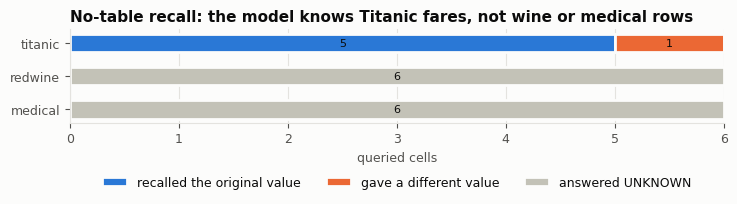

PassengerId 1-3 without a table: 6/6 fares recalled
PassengerId 1-3 in a table with changed fares: 48/48 copied correctly, 0 reversions


In [13]:
OUTCOMES = [("correct", "recalled the original value", FORMAT_COLORS["csv"]),
            ("other", "gave a different value", FORMAT_COLORS["json"]),
            ("unknown", "answered UNKNOWN", NEUTRAL)]
fig, ax = plt.subplots(figsize=(7.5, 2.6))
left = np.zeros(len(probes))
for key, label, color in OUTCOMES:
    ax.barh(probes.index, probes[key], left=left, color=color, height=0.55, edgecolor=SURFACE, linewidth=2, label=label)
    for y, (value, start) in enumerate(zip(probes[key], left)):
        if value:
            ax.text(start + value / 2, y, str(value), ha="center", va="center", color=INK, fontsize=8)
    left += probes[key].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("queried cells")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncols=3)
ax.set_title("No-table recall: the model knows Titanic fares, not wine or medical rows", loc="left",
             fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

canonical = {k: week4["stages"][k] for k in ["canonical_prior", "canonical_lookup"]}
print("PassengerId 1-3 without a table:",
      f'{canonical["canonical_prior"]["target_values_correct"]}/{canonical["canonical_prior"]["target_values"]} fares recalled')
print("PassengerId 1-3 in a table with changed fares:",
      f'{canonical["canonical_lookup"]["target_values_correct"]}/{canonical["canonical_lookup"]["target_values"]} copied correctly, '
      f'{canonical["canonical_lookup"]["original_value_reversions"]} reversions')

## 6. Round 4: selection and joins

Strict success requires every value correct plus exactly the expected keys and string values. Unlike the ID lookups, a few answers failed here, and most involve `NOT_FOUND`: answering it for a row that exists, or giving a value for the absent query (a combination of attribute values that matches no row).

In [14]:
r4 = pd.DataFrame([
    dict(task=task, format=fmt, strict=fraction(g["strict_correct"], g["requests"]),
         present=fraction(g["present_correct"], g["present_n"]), absent=fraction(g["absent_correct"], g["absent_n"]),
         reversions=g["reversions"])
    for task, by_format in selection["primary"].items() for fmt, g in by_format.items()
]).set_index(["task", "format"])
r4

strict           present          absent  reversions
task      format                                                              
attribute csv      46/48 (95.8%)  144/144 (100.0%)   46/48 (95.8%)           0
          json     47/48 (97.9%)   143/144 (99.3%)  48/48 (100.0%)           0
          xml      47/48 (97.9%)   143/144 (99.3%)  48/48 (100.0%)           0
          txt     48/48 (100.0%)  144/144 (100.0%)  48/48 (100.0%)           0
join      csv     48/48 (100.0%)  144/144 (100.0%)  48/48 (100.0%)           0
          json    48/48 (100.0%)  144/144 (100.0%)  48/48 (100.0%)           0
          xml     48/48 (100.0%)  144/144 (100.0%)  48/48 (100.0%)           0
          txt      46/48 (95.8%)  144/144 (100.0%)   46/48 (95.8%)           0

In [15]:
secondary = pd.DataFrame({k: dict(strict=fraction(v["strict_correct"], v["requests"]),
                                  present=fraction(v["present_correct"], v["present_n"]),
                                  absent=fraction(v["absent_correct"], v["absent_n"]))
                          for k, v in selection["secondary"].items()}).T
secondary

,strict,present,absent
calibration,32/32 (100.0%),96/96 (100.0%),32/32 (100.0%)
synthetic,58/64 (90.6%),187/192 (97.4%),63/64 (98.4%)
baseline,48/48 (100.0%),144/144 (100.0%),48/48 (100.0%)
repeat,24/24 (100.0%),72/72 (100.0%),24/24 (100.0%)


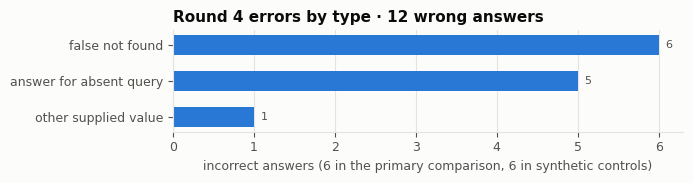

In [16]:
errors = pd.Series(selection["error_categories"]).sort_values()
# The error categories cover the primary comparison and the synthetic controls (the other components had no errors)
wrong = {name: g["present_n"] - g["present_correct"] + g["absent_n"] - g["absent_correct"]
         for name, g in [("primary", selection["primary_total"]), ("synthetic", selection["secondary"]["synthetic"])]}
assert sum(wrong.values()) == errors.sum()
fig, ax = plt.subplots(figsize=(7, 1.9))
ax.barh([e.replace("_", " ") for e in errors.index], errors, color=FORMAT_COLORS["csv"], height=0.55)
for y, value in enumerate(errors):
    ax.text(value, y, f"  {value}", va="center", color=MUTED, fontsize=8)
ax.set_xlabel(f"incorrect answers ({wrong['primary']} in the primary comparison, {wrong['synthetic']} in synthetic controls)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Round 4 errors by type · {errors.sum()} wrong answers", loc="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()